# Unsupervised Learning #

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.datasets import get_rdataset
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from ISLP import load_data
from sklearn.cluster import (KMeans,
                            AgglomerativeClustering)
from scipy.cluster.hierarchy import (dendrogram,
                                    cut_tree)
from ISLP.cluster import compute_linkage                                    

## Principal Components Analysis ##

In [3]:
USArrests = get_rdataset('USArrests').data
USArrests.head(5)

,Murder,Assault,UrbanPop,Rape
rownames,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


In [4]:
USArrests.mean()

Murder        7.788
Assault     170.760
UrbanPop     65.540
Rape         21.232
dtype: float64

In [5]:
USArrests.var()

Murder        18.970465
Assault     6945.165714
UrbanPop     209.518776
Rape          87.729159
dtype: float64

In [6]:
USArrests.describe()

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


Os dados estão em escalas distintas, como foi lido no capítulo os dados devem estar padronizados pois o PCA busca a maior variabilidade dos dados para criar os componentes principais, esse dataset tem o `Assault` com a maior escala e variabilidade, com isso as outras colunas comparada a essa seria menos relevante e teria menos informação a ser extraída.

In [7]:
scaler = StandardScaler(with_std=True,
                        with_mean=True)#por padrão esses hiperparâmetros já vem como verdadeiro, está só reforçando para leitura
USArrests_scaled = scaler.fit_transform(USArrests)
pd.DataFrame(USArrests_scaled, columns=USArrests.columns).describe().round(5)

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.00000,50.00000,50.00000
mean,-0.00000,0.00000,-0.00000,0.00000
std,1.01015,1.01015,1.01015,1.01015
min,-1.62069,-1.52436,-2.34066,-1.50255
25%,-0.86114,-0.74861,-0.77045,-0.66402
50%,-0.12478,-0.14255,0.03210,-0.12208
75%,0.80293,0.94836,0.85210,0.53310
max,2.22927,2.01503,1.77678,2.67120


In [8]:
pcaUS = PCA()
pcaUS.fit(USArrests_scaled)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [9]:
pcaUS.mean_

array([-7.10542736e-17,  1.38777878e-16, -4.39648318e-16,  8.59312621e-16])

`Scores` - pontuação dos componentes.

Valores dos dados após a projeção dos componentes principal

In [10]:
scores = pcaUS.transform(USArrests_scaled)
scores[:5]

array([[ 0.98556588, -1.13339238, -0.44426879, -0.15626714],
       [ 1.95013775, -1.07321326,  2.04000333,  0.43858344],
       [ 1.76316354,  0.74595678,  0.05478082,  0.83465292],
       [-0.14142029, -1.11979678,  0.11457369,  0.1828109 ],
       [ 2.52398013,  1.54293399,  0.5985568 ,  0.34199648]])

`Loadings` - Pesos

Peso de cada variável/coluna/preditor para os n componentes principais

*o retorno dos `components_` vem no formato de cada linha ser um componente principal*

In [11]:
pcaUS.components_

array([[ 0.53589947,  0.58318363,  0.27819087,  0.54343209],
       [-0.41818087, -0.1879856 ,  0.87280619,  0.16731864],
       [-0.34123273, -0.26814843, -0.37801579,  0.81777791],
       [-0.6492278 ,  0.74340748, -0.13387773, -0.08902432]])

In [12]:
pd.DataFrame(pcaUS.components_, 
             index=['PC1', 'PC2', 'PC3', 'PC4'], 
             columns=USArrests.columns)

,Murder,Assault,UrbanPop,Rape
PC1,0.535899,0.583184,0.278191,0.543432
PC2,-0.418181,-0.187986,0.872806,0.167319
PC3,-0.341233,-0.268148,-0.378016,0.817778
PC4,-0.649228,0.743407,-0.133878,-0.089024


In [13]:
print('Vendo de forma transposta como os exemplos do livro')
pd.DataFrame(pcaUS.components_.T, 
             columns=['PC1', 'PC2', 'PC3', 'PC4'], 
             index=USArrests.columns)

Vendo de forma transposta como os exemplos do livro


,PC1,PC2,PC3,PC4
Murder,0.535899,-0.418181,-0.341233,-0.649228
Assault,0.583184,-0.187986,-0.268148,0.743407
UrbanPop,0.278191,0.872806,-0.378016,-0.133878
Rape,0.543432,0.167319,0.817778,-0.089024


In [14]:
print(scores[:5])
print('Calculando a projeção "manualmente" dos dados com os pesos:')
print(USArrests_scaled[:5] @ pcaUS.components_.T)

[[ 0.98556588 -1.13339238 -0.44426879 -0.15626714]
 [ 1.95013775 -1.07321326  2.04000333  0.43858344]
 [ 1.76316354  0.74595678  0.05478082  0.83465292]
 [-0.14142029 -1.11979678  0.11457369  0.1828109 ]
 [ 2.52398013  1.54293399  0.5985568   0.34199648]]
Calculando a projeção "manualmente" dos dados com os pesos:
[[ 0.98556588 -1.13339238 -0.44426879 -0.15626714]
 [ 1.95013775 -1.07321326  2.04000333  0.43858344]
 [ 1.76316354  0.74595678  0.05478082  0.83465292]
 [-0.14142029 -1.11979678  0.11457369  0.1828109 ]
 [ 2.52398013  1.54293399  0.5985568   0.34199648]]


**BIPLOT**

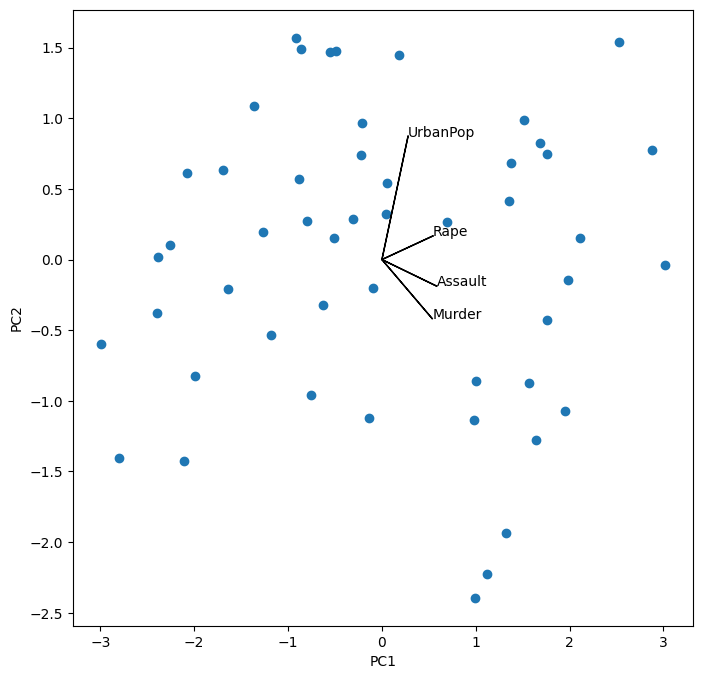

In [15]:
i, j = 0, 1 # componentes selecionados
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(scores[:, i], scores[:, j])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pcaUS.components_.shape[1]):
    ax.arrow(0, 0, pcaUS.components_[i,k], pcaUS.components_[j,k])
    ax.text(pcaUS.components_[i,k],
            pcaUS.components_[j,k],
            USArrests.columns[k])

Invertendo um eixo, vale ressaltar que os valores são únicos porém o sinal pode ser invertido dependendo da forma de calcular, de linguagem ou biblioteca, podemos inverter qualquer um ou todos, importante é quando inverter o loadings/pesos tambem inverter o scores/pontuação dos componentes 

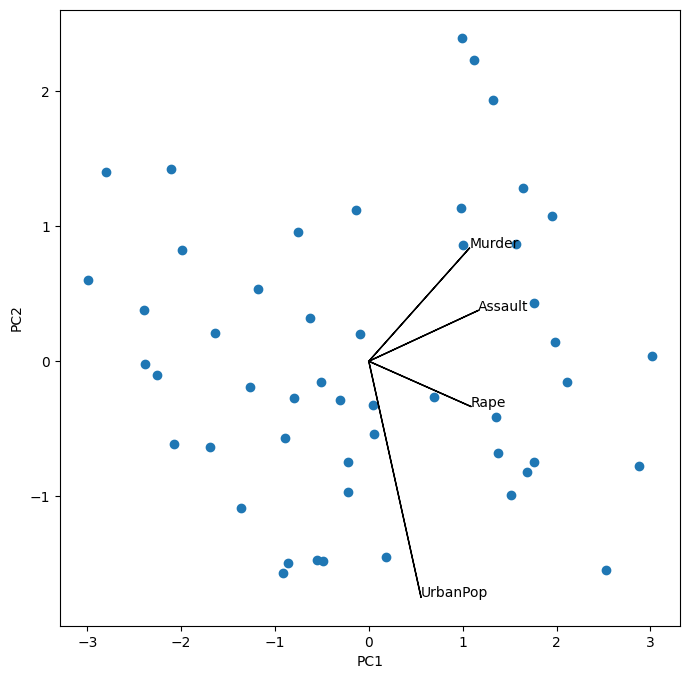

In [16]:
scale_arrow = s_ = 2
scores[:, 1] *= -1
pcaUS.components_[1] *=-1

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(scores[:, i], scores[:, j])
ax.set_xlabel('PC%d' % (i+1))
ax.set_ylabel('PC%d' % (j+1))
for k in range(pcaUS.components_.shape[1]):
    ax.arrow(0, 0, s_ * pcaUS.components_[i,k], s_ * pcaUS.components_[j,k])
    ax.text(s_*pcaUS.components_[i,k],
            s_*pcaUS.components_[j,k],
            USArrests.columns[k])

In [17]:
scores.std(0, ddof=1)

array([1.5908673 , 1.00496987, 0.6031915 , 0.4206774 ])

In [18]:
pcaUS.explained_variance_

array([2.53085875, 1.00996444, 0.36383998, 0.17696948])

In [19]:
pcaUS.explained_variance_ratio_

array([0.62006039, 0.24744129, 0.0891408 , 0.04335752])

In [20]:
%%capture

fig, axes = plt.subplots(1,2,figsize=(15,6))
ticks = np.arange(pcaUS.n_components_)+1
ax = axes[0]
ax.plot(ticks,
        pcaUS.explained_variance_ratio_,
        marker='o')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Proportion of Variance Explained')
ax.set_ylim([0,1])
ax.set_xticks(ticks)


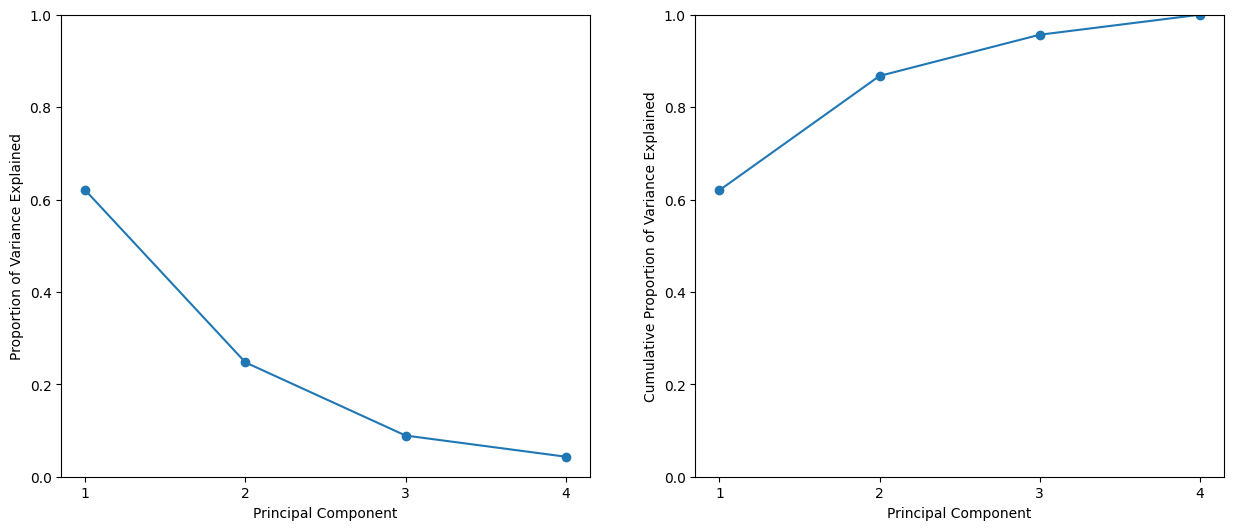

In [21]:
ax=axes[1]
ax.plot(ticks,
        pcaUS.explained_variance_ratio_.cumsum(),
        marker='o')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Cumulative Proportion of Variance Explained')
ax.set_ylim([0,1])
ax.set_xticks(ticks)
fig

In [22]:
a = np.array([1,2,8,-3])
np.cumsum(a)

array([ 1,  3, 11,  8])

## Matrix Completion ##

Origem dos dados da matrix de pesos/loadings explorando SVD(Singular value decoposition)

In [52]:
X = USArrests_scaled
U, D, V = np.linalg.svd(X, full_matrices=False) #hiperparametro por padrão já vem como true
U.shape, D.shape, V.shape

((50, 4), (4,), (4, 4))

Nesse cenário os sinais ficaram invertidos, mas os valores são os mesmo, SVD contém uma solução do PCA

In [53]:
print('V:\n', V)
print('PCA Components:\n', pcaUS.components_)

V:
 [[-0.53589947 -0.58318363 -0.27819087 -0.54343209]
 [-0.41818087 -0.1879856   0.87280619  0.16731864]
 [ 0.34123273  0.26814843  0.37801579 -0.81777791]
 [ 0.6492278  -0.74340748  0.13387773  0.08902432]]
PCA Components:
 [[ 0.53589947  0.58318363  0.27819087  0.54343209]
 [ 0.41818087  0.1879856  -0.87280619 -0.16731864]
 [-0.34123273 -0.26814843 -0.37801579  0.81777791]
 [-0.6492278   0.74340748 -0.13387773 -0.08902432]]


A matriz U corresponde a uma versão padronizada da matriz de escores da PCA (em que cada coluna é padronizada de modo que a soma de seus quadrados seja igual a um). Se multiplicarmos cada coluna de U pelo elemento correspondente de D, recuperamos exatamente os escores da PCA (exceto por uma inversão de sinal sem significado).

In [57]:
print((U * D[None,:])[:3])
print("Scores/pontuacões dos PCA's:\n",scores[:3])


[[-0.98556588 -1.13339238  0.44426879  0.15626714]
 [-1.95013775 -1.07321326 -2.04000333 -0.43858344]
 [-1.76316354  0.74595678 -0.05478082 -0.83465292]]
Scores/pontuacões dos PCA's:
 [[ 0.98556588  1.13339238 -0.44426879 -0.15626714]
 [ 1.95013775  1.07321326  2.04000333  0.43858344]
 [ 1.76316354 -0.74595678  0.05478082  0.83465292]]


Agora que sabemos chegar a matriz de scores com SVD, podemos calcular uma matriz aproximada de scores quando a matriz de origem tem dados nulos, podendo completar com valores aproximados os dados nulos

In [ ]:
#remover dados aleatoriamente de X
n_omit = 20
np.random.seed(15)
r_idx = np.random.choice(np.arange(X.shape[0]), n_omit, replace=False)
c_idx = np.random.choice(np.arange(X.shape[1]), n_omit, replace=True)

Xna = X.copy()
Xna[r_idx, c_idx] = np.nan
Xna[:10]

array([[ 1.25517927,  0.79078716, -0.52619514, -0.00345116],
       [ 0.51301858,  1.11805959, -1.22406668,  2.50942392],
       [ 0.07236067,  1.49381682,  1.00912225,  1.05346626],
       [ 0.23470832,  0.23321191, -1.08449238,         nan],
       [ 0.28109336,  1.2756352 ,  1.77678094,  2.08881393],
       [ 0.02597562,  0.40290872,  0.86954794,  1.88390137],
       [-1.04088037, -0.73648418,  0.79976079, -1.09272319],
       [-0.43787481,  0.81502956,  0.45082502, -0.58583422],
       [ 1.76541475,  1.99078607,  1.00912225,  1.1505301 ],
       [        nan,  0.48775713, -0.38662083,  0.49265293]])

In [64]:
def low_rank(X, M=1):
    # M representa a quantidade de componentes principais utilizados
    U, D, V = np.linalg.svd(X)
    # L são os Scores/pontuações do componentes principais de M
    L = U[:, :M] * D[None, :M]
    #reconstrução da matriz agora com os pesos
    return L @ V[:M]

Para calcular o SVD a matriz não pode ter dados nulos, preenchendo os valores nulos com a média nesse caso

In [84]:
Xhat = Xna.copy()
X_bar = np.nanmean(Xhat, axis=0)
Xhat[r_idx, c_idx] = X_bar[c_idx]
Xhat[:10]

array([[ 1.25517927,  0.79078716, -0.52619514, -0.00345116],
       [ 0.51301858,  1.11805959, -1.22406668,  2.50942392],
       [ 0.07236067,  1.49381682,  1.00912225,  1.05346626],
       [ 0.23470832,  0.23321191, -1.08449238,  0.04508076],
       [ 0.28109336,  1.2756352 ,  1.77678094,  2.08881393],
       [ 0.02597562,  0.40290872,  0.86954794,  1.88390137],
       [-1.04088037, -0.73648418,  0.79976079, -1.09272319],
       [-0.43787481,  0.81502956,  0.45082502, -0.58583422],
       [ 1.76541475,  1.99078607,  1.00912225,  1.1505301 ],
       [-0.00368923,  0.48775713, -0.38662083,  0.49265293]])

In [85]:
thresh = 1e-7
rel_err = 1
count = 0
# Matriz booleana indicando os valores nulos
ismiss = np.isnan(Xna)
# Resíduos de X aproximado
mssold = np.mean(Xhat[~ismiss]**2)
# Resíduos de X original que contem dados nulos
mss0 = np.mean(Xna[~ismiss]**2)

In [86]:
ismiss[:10]

array([[False, False, False, False],
       [False, False, False, False],
       [False, False, False, False],
       [False, False, False,  True],
       [False, False, False, False],
       [False, False, False, False],
       [False, False, False, False],
       [False, False, False, False],
       [False, False, False, False],
       [ True, False, False, False]])

In [ ]:
while rel_err > thresh:
    count +=1
    #Step 2(a)
    Xapp = low_rank(Xhat, M=1)
    #Step 2(b)
    Xhat[ismiss] = Xapp[ismiss]
    #Step 2(c)
    mss = np.mean(((Xna - Xapp)[~ismiss])**2)
    #erro relativo
    rel_err = (mssold - mss) / mss0
    mssold = mss

    print("Iteration: {0}, MSS{1:.3f}, Rel.Err {2:.2e}".format(count, mss, rel_err))

Iteration: 1, MSS0.395, Rel.Err 5.99e-01
Iteration: 2, MSS0.382, Rel.Err 1.33e-02
Iteration: 3, MSS0.381, Rel.Err 1.44e-03
Iteration: 4, MSS0.381, Rel.Err 1.79e-04
Iteration: 5, MSS0.381, Rel.Err 2.58e-05
Iteration: 6, MSS0.381, Rel.Err 4.22e-06
Iteration: 7, MSS0.381, Rel.Err 7.65e-07
Iteration: 8, MSS0.381, Rel.Err 1.48e-07
Iteration: 9, MSS0.381, Rel.Err 2.95e-08


Calcular a correlação entre os valores preenchidos

In [ ]:
np.corrcoef(Xapp[ismiss], X[ismiss])[0,1]

(np.float64(0.7113567434297361), np.float64(0.7113567434297361))

In [92]:
print('X_hat:\n',Xhat[ismiss])
print('X original:\n',X[ismiss])

X_hat:
 [-0.02170075  0.32078918 -1.33266731 -0.29922154 -0.31682263 -0.75246172
 -0.68681709 -0.7142356   1.08083338 -1.93098721 -0.19258441  0.29386874
 -0.42544276 -0.24624544  0.23813613  0.3005312  -0.16527922 -1.45940706
 -0.4591732  -0.14943681]
X original:
 [-0.18679398  2.22926518 -1.07115345 -0.74860538 -0.26375734 -1.1800355
 -0.74860538 -0.83345379  0.83771388 -1.52436225 -0.13286962 -0.66980002
 -0.68289807 -1.01768785  1.25517927  1.00912225 -0.61527217 -1.29599811
 -1.85215107 -0.38662083]


## Clustering ##

In [ ]:
#Criando um data set de duas colunas e diferenciando os primeiros 25 registros
np.random.seed(0)
X = np.random.standard_normal((50,2))
X[:25, 0] += 3
X[:25, 1] -=4
X[:5], X[-5:]

(array([[ 4.76405235, -3.59984279],
        [ 3.97873798, -1.7591068 ],
        [ 4.86755799, -4.97727788],
        [ 3.95008842, -4.15135721],
        [ 2.89678115, -3.5894015 ]]),
 array([[-0.40317695,  1.22244507],
        [ 0.20827498,  0.97663904],
        [ 0.3563664 ,  0.70657317],
        [ 0.01050002,  1.78587049],
        [ 0.12691209,  0.40198936]]))

### K-Means ###

In [102]:
kmeans = KMeans(n_clusters=2, random_state=2, n_init=20).fit(X)
kmeans.labels_

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1], dtype=int32)

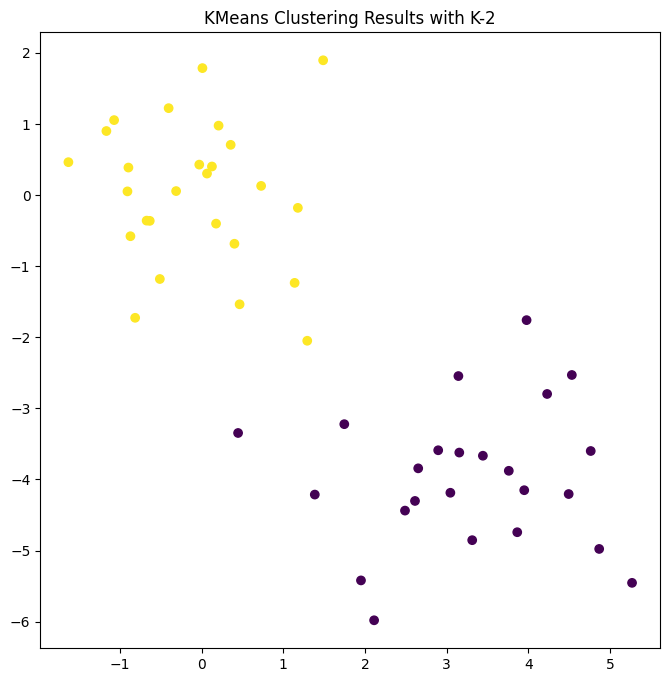

In [ ]:
fig, ax = plt.subplots(1,1,figsize=(8,8))
ax.scatter(X[:, 0], X[:, 1], c=kmeans.labels_)
ax.set_title("KMeans Clustering Results with K=2");

Classificação "correta", separou em dois grupos de 25 registros conforme proposto na construção de X.

A seguir a divisão será em 3 grupos

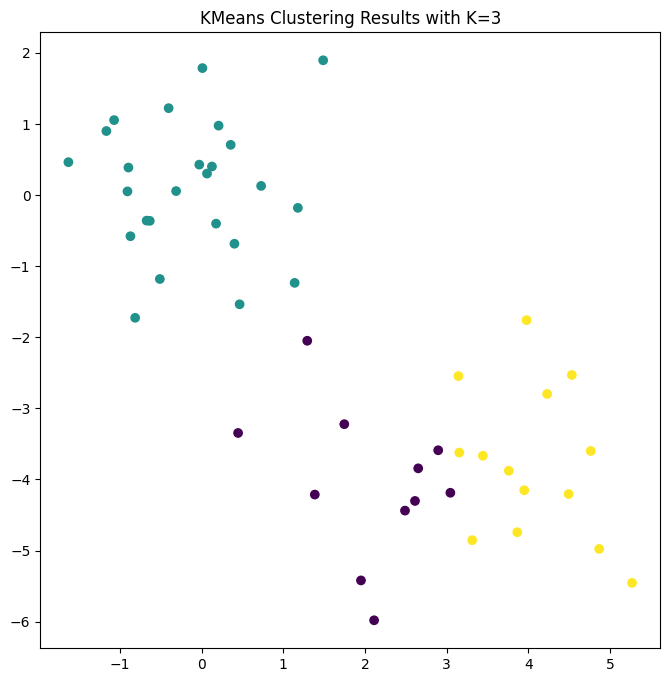

In [106]:
kmeans = KMeans(n_clusters=3, random_state=3, n_init=20).fit(X)
fig, ax = plt.subplots(1,1,figsize=(8,8))
ax.scatter(X[:, 0], X[:, 1], c=kmeans.labels_)
ax.set_title("KMeans Clustering Results with K=3");

Importância do hiperparâmetro n_init.

O capítulo nos mostra que dependendo do ponto de inicialização do centroide o resultado pode ser diverso, com isso vários locais ótimos podem ser o resultado. Ao aumentar ou reduzir o valor sempre será reservado o melhor modelo, o que tiver a menor Inercia/menor distância de seus membros para o centroide

In [108]:
kmeans1 = KMeans(n_clusters=3, random_state=3, n_init=1).fit(X)
kmeans20 = KMeans(n_clusters=3, random_state=3, n_init=20).fit(X)

kmeans1.inertia_, kmeans20.inertia_

(76.85131986999251, 75.06261242745384)

### Hierarchical Cluestering ###


In [110]:
# Apenas simplificando o nome
HClust = AgglomerativeClustering
hc_comp = HClust(distance_threshold=0,
                 n_clusters=None,
                 linkage='complete')
hc_comp.fit(X)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",None
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'complete'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",0
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


In [111]:
hc_avg = HClust(distance_threshold=0,
                n_clusters=None,
                linkage='average')
hc_avg.fit(X)

hc_sing = HClust(distance_threshold=0,
                n_clusters=None,
                linkage='single')
hc_sing.fit(X)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",None
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'single'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",0
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


In [112]:
D = np.zeros((X.shape[0], X.shape[0]))
for i in range (X.shape[0]):
    x_ = np.multiply.outer(np.ones(X.shape[0]), X[i])
    D[i] = np.sqrt(np.sum((X - x_)**2,1))
hc_sing_pre = HClust(distance_threshold=0,
                     n_clusters=None,
                     metric='precomputed',
                     linkage='single')
hc_sing_pre.fit(D)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",None
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" is accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and affinity is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'precomputed'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'single'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",0
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False


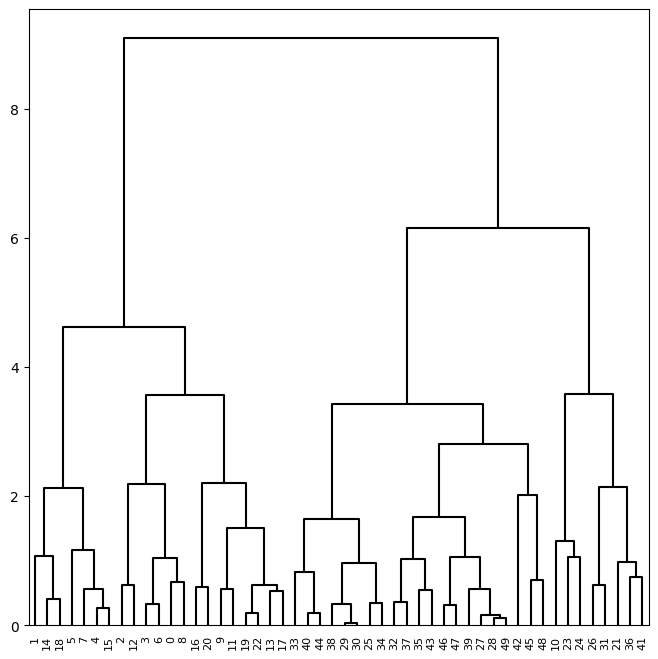

In [114]:
cargs = {'color_threshold':-np.inf,
         'above_threshold_color':'black'}
linkage_comp = compute_linkage(hc_comp)
fig, ax = plt.subplots(1,1,figsize=(8,8))
dendrogram(linkage_comp, ax=ax, **cargs);

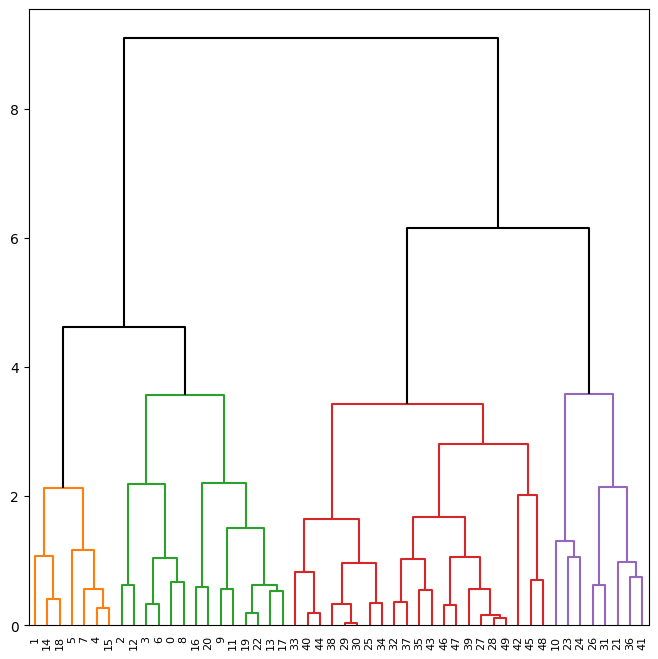

In [115]:
fig, ax = plt.subplots(1,1,figsize=(8,8))
dendrogram(linkage_comp, ax=ax, color_threshold=4, above_threshold_color='black');

"Cortando" a árvore para um número x de clusters, nesse caso 4

In [118]:
cut_tree(linkage_comp, n_clusters=4).T

array([[0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 2, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 2,
        0, 2, 2, 3, 2, 3, 3, 3, 3, 2, 3, 3, 3, 3, 2, 3, 3, 3, 3, 2, 3, 3,
        3, 3, 3, 3, 3, 3]])

"Cortando" uma árvore pela altura/distance treshold dela, nesse caso 5

In [121]:
cut_tree(linkage_comp, height=5).T

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
        0, 1, 1, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2,
        2, 2, 2, 2, 2, 2]])

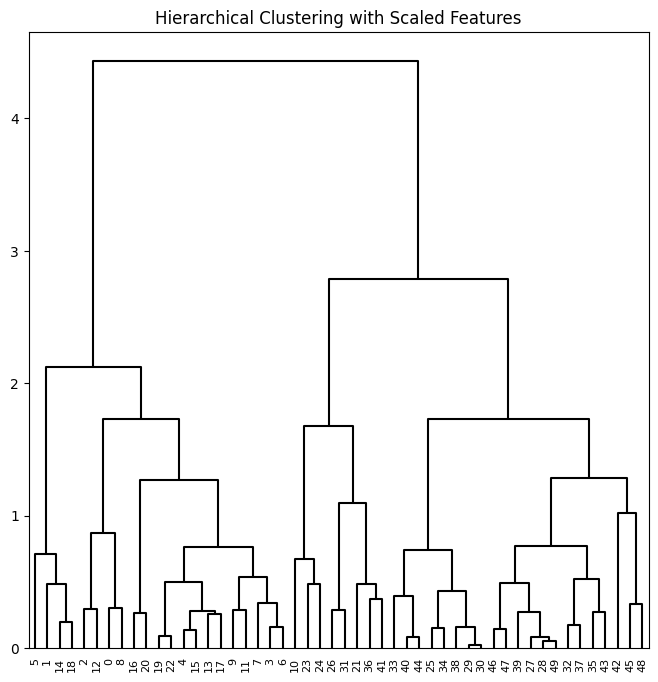

In [123]:
scaler = StandardScaler()
X_scale = scaler.fit_transform(X)
hc_comp_scale = HClust(distance_threshold=0,
                       n_clusters=None,
                       linkage='complete').fit(X_scale)
linkage_comp_scale = compute_linkage(hc_comp_scale)
fig, ax = plt.subplots(1,1, figsize=(8,8))
dendrogram(linkage_comp_scale, ax=ax, **cargs)
ax.set_title('Hierarchical Clustering with Scaled Features');

Outro exemplo de utilização da classe de clusterização com matriz precomputada de dissimilaridades.

Um novo data set com 3 colunas

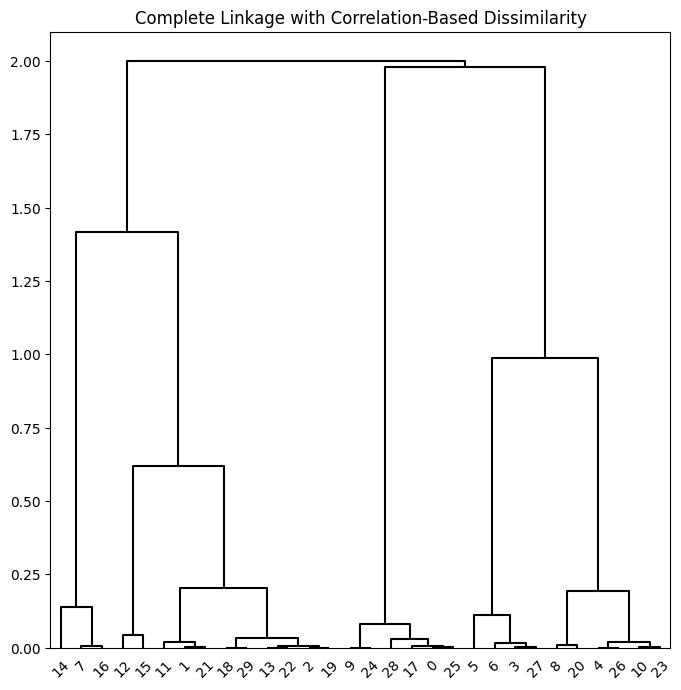

In [124]:
X = np.random.standard_normal((30,3))
#Matriz de correlação menos 1 nos dá uma matriz de dissimilaridades 
corD = 1 - np.corrcoef(X)
hc_cor = HClust(linkage='complete',
                distance_threshold=0,
                n_clusters=None,
                metric='precomputed')
hc_cor.fit(corD)
linkage_cor = compute_linkage(hc_cor)
fig, ax = plt.subplots(1,1, figsize=(8,8))
dendrogram(linkage_cor, ax=ax, **cargs)
ax.set_title("Complete Linkage with Correlation-Based Dissimilarity");